
# **Import libraries and load dataset**


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import clone

# Load dataset
df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())


Dataset loaded successfully!
Shape: (1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  S

# **Initial EDA**

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   

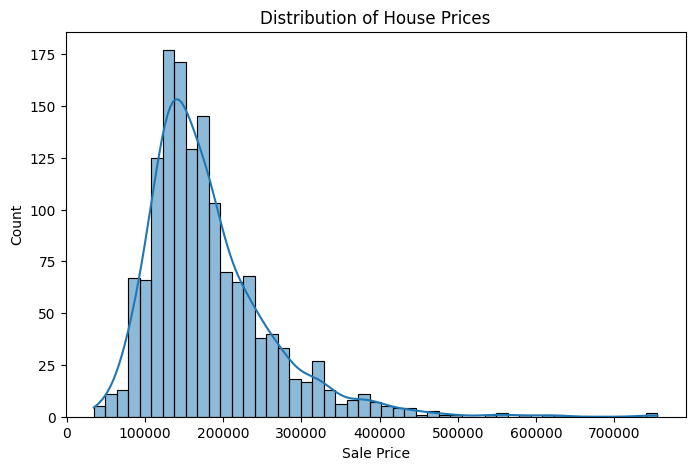

In [2]:

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDescriptive Statistics:")
print(df.describe())

# Target variable distribution
plt.figure(figsize=(8,5))
sns.histplot(df['SalePrice'], kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.show()


# **Feature selection**


# Feature Selection Discussion

The following features are selected because they may influence house prices:

1. OverallQual: Overall quality of the house.
2. GrLivArea: Above-ground living area.
3. TotalBsmtSF: Total basement area.
4. GarageCars: Garage capacity.
5. YearBuilt: Construction year.
6. FullBath: Number of full bathrooms.
7. BedroomAbvGr: Number of bedrooms.

These features are expected to have relationships with SalePrice.

Other numerical and categorical features will also be considered by the model.


# **Correlation heatmap**

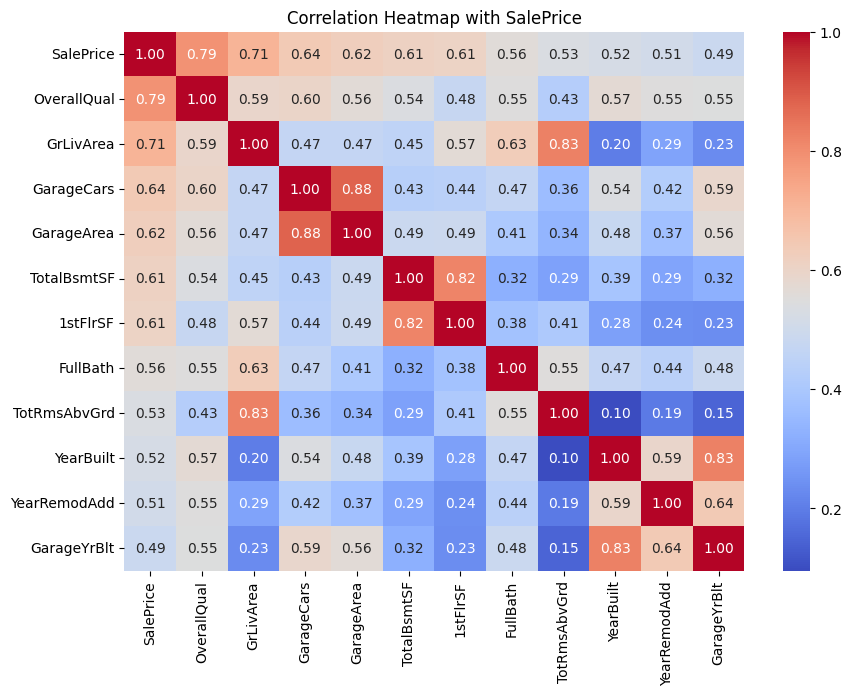

In [3]:

numeric_df = df.select_dtypes(include=np.number)

top_corr = numeric_df.corr()['SalePrice'].abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(10,7))
sns.heatmap(
    df[top_corr].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap with SalePrice')
plt.show()


# **Prepare data and handle missing values**

In [4]:

# Remove ID because it is only an identifier
X = df.drop(columns=['SalePrice', 'Id'])
y = df['SalePrice']

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Handle missing values and encode categories
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Missing values handled through preprocessing.")
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numeric_features))


Missing values handled through preprocessing.
Categorical features: 43
Numerical features: 36


# **Train/Test split (80/20)**

In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 1168
Testing records: 292


# **Train Linear Regression model**

In [7]:

model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


# **Model evaluation**

In [8]:

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")


Model Evaluation Results
------------------------
Mean Squared Error: 979376460.09
Root Mean Squared Error: 31294.99
R2 Score: 0.8723
R2 Percentage: 87.23 %


# **Actual vs Predicted Prices**

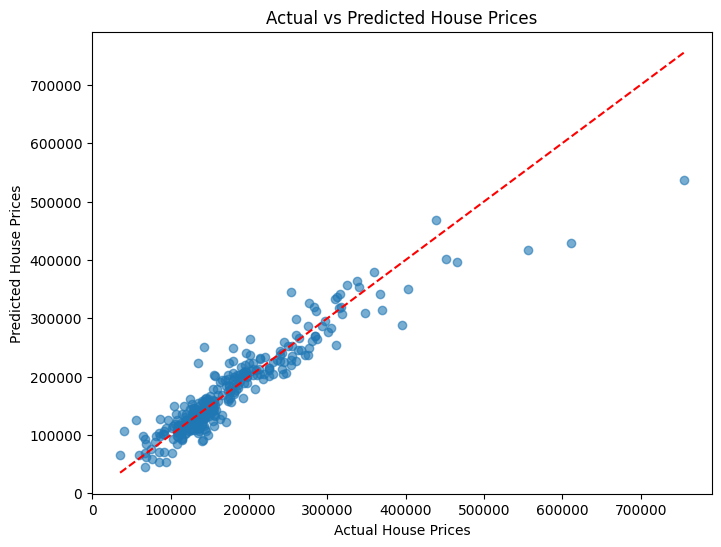

In [9]:

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted House Prices')
plt.show()


# **Residual plot**

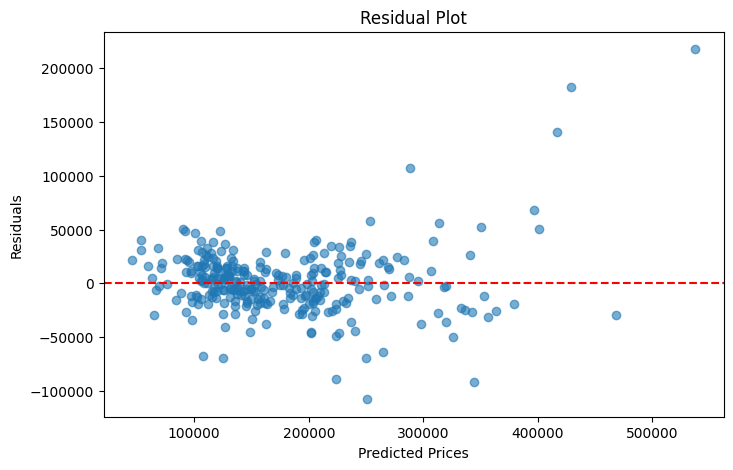

In [10]:

residuals = y_test - y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()


# **Coefficient analysis**

Top 15 Important Features:
                       Feature   Coefficient  Absolute Impact
78   cat__Neighborhood_NoRidge  41901.268218     41901.268218
85   cat__Neighborhood_StoneBr  39134.933544     39134.933544
124      cat__RoofMatl_ClyTile -29057.711990     29057.711990
259             cat__PoolQC_Ex  28020.792433     28020.792433
261             cat__PoolQC_Gd -24972.333443     24972.333443
79   cat__Neighborhood_NridgHt  24777.963772     24777.963772
101       cat__Condition2_PosN -24387.894785     24387.894785
134   cat__Exterior1st_BrkFace  23198.043843     23198.043843
153   cat__Exterior2nd_ImStucc  21429.506595     21429.506595
74   cat__Neighborhood_Mitchel -21248.184226     21248.184226
49        cat__LandContour_Bnk -20468.188112     20468.188112
180           cat__BsmtQual_Ex  20061.527068     20061.527068
221        cat__KitchenQual_Ex  19445.880060     19445.880060
50        cat__LandContour_HLS  18920.803465     18920.803465
70   cat__Neighborhood_Edwards -17223.30488

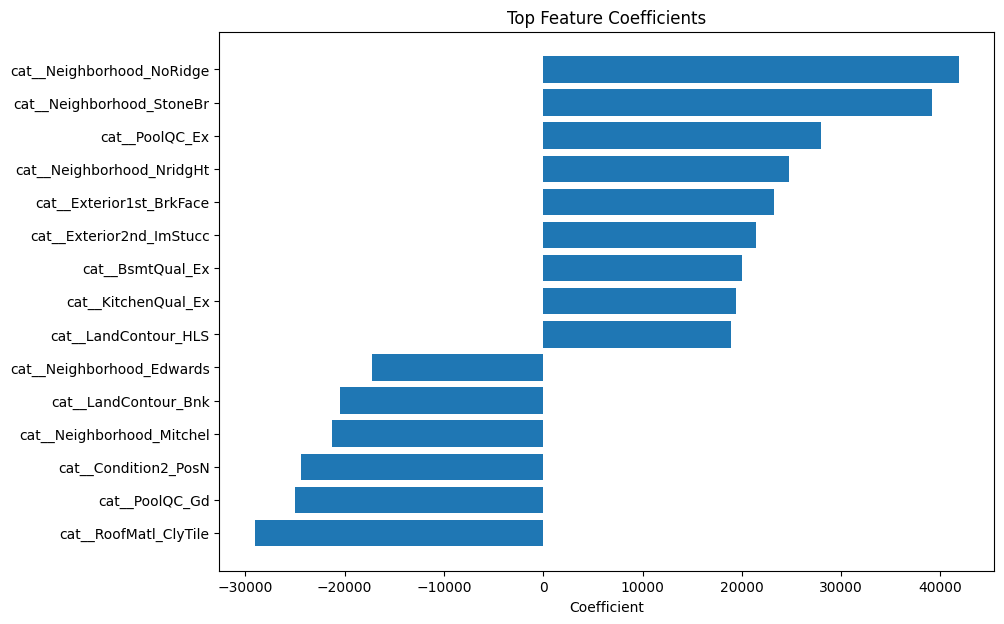

In [11]:

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = model.named_steps['regressor'].coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df['Absolute Impact'] = coef_df['Coefficient'].abs()

coef_df = coef_df.sort_values(
    'Absolute Impact', ascending=False
)

print("Top 15 Important Features:")
print(coef_df.head(15))

# Visualize positive and negative coefficients
top_coef = coef_df.head(15).sort_values('Coefficient')

plt.figure(figsize=(10,7))
plt.barh(top_coef['Feature'], top_coef['Coefficient'])
plt.title('Top Feature Coefficients')
plt.xlabel('Coefficient')
plt.show()


# **Bonus – Ridge and Lasso comparison**

In [12]:

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=10),
    'Lasso': Lasso(alpha=100, max_iter=10000)
}

results = []

for name, regressor in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('regressor', regressor)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
print(results_df)


               Model          RMSE  R2 Score
0  Linear Regression  31294.990974  0.872316
1              Ridge  34565.369089  0.844235
2              Lasso  28304.205228  0.895555


# **Final conclusion**


# House Price Prediction – Conclusion

## Key Findings

1. The Ames Housing dataset was analyzed to understand factors affecting house prices.
2. Missing numerical and categorical values were handled.
3. Categorical variables were converted using One-Hot Encoding.
4. The dataset was divided into 80% training and 20% testing data.
5. A Linear Regression model was trained.
6. Model performance was evaluated using MSE, RMSE and R2 score.
7. Actual vs predicted prices and residual plots were used to evaluate predictions.
8. Ridge and Lasso regression were compared with Linear Regression.

## Conclusion

Linear Regression provides a baseline approach for predicting house prices based on property characteristics. Model evaluation helps understand prediction accuracy and limitations. Regularized regression models can help control overfitting.

## Future Improvements

More advanced machine learning algorithms and feature engineering can improve prediction performance.
